In [ ]:
import io
import sys
import zipfile
from glob import glob
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader
from matplotlib.collections import LineCollection
from pyproj import Transformer

sys.path.append("../..")
from src.data import dataset_utils as du
from src.data import graph_utils as gu

ZARR_PATH = "/work/ka1176/shared_data/2025-wwm-emulator-schism/processed_RUN04b_JUWELS_wpile.zarr"
BOUNDARY_NODES_CSV = "../../src/data/node_selection/boundary_nodes.csv"
DATA_CRS = ccrs.UTM(32)  # SCHISM_hgrid_node_x/y are projected UTM zone 32N
LONLAT_TRANSFORMER = Transformer.from_crs("epsg:32632", "epsg:4326", always_xy=True)

ds_true = xr.open_dataset(ZARR_PATH, engine="zarr", chunks="auto")

node_x = ds_true["SCHISM_hgrid_node_x"].values
node_y = ds_true["SCHISM_hgrid_node_y"].values

print(f"node_x range: [{node_x.min():.2f}, {node_x.max():.2f}]")
print(f"node_y range: [{node_y.min():.2f}, {node_y.max():.2f}]")
print(f"Total nodes: {len(node_x)}, total time steps: {ds_true.sizes['time']}")

node_x range: [-170936.47, 588878.00]
node_y range: [5550339.00, 6211776.00]
Total nodes: 589428, total time steps: 8760


/tmp/ipykernel_3219291/3658512320.py:28: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 20. This could degrade performance. Instead, consider rechunking after loading.
  ds_true = xr.open_dataset(ZARR_PATH, engine="zarr", chunks="auto")
/tmp/ipykernel_3219291/3658512320.py:28: UserWarning: The specified chunks separate the stored chunks along dimension "nSCHISM_hgrid_edge" starting at index 1677719. This could degrade performance. Instead, consider rechunking after loading.
  ds_true = xr.open_dataset(ZARR_PATH, engine="zarr", chunks="auto")
/tmp/ipykernel_3219291/3658512320.py:28: UserWarning: The specified chunks separate the stored chunks along dimension "two" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds_true = xr.open_dataset(ZARR_PATH, engine="zarr", chunks="auto")
/tmp/ipykernel_3219291/3658512320.py:28: UserWarning: The specified chunks separate the stored chunks along

In [ ]:
from lightning_utilities.core.rank_zero import rank_zero_only
rank_zero_only.rank = 0

In [ ]:
nx = ds_true.SCHISM_hgrid_node_x
ny = ds_true.SCHISM_hgrid_node_y
ed = ds_true.SCHISM_hgrid_edge_nodes.isel(two=0)

In [ ]:
MAX_NODES_PARTITION = 500

# --- Build adjacency and partition the domain, exactly as predict_gcn.py does ---
adjacency = gu.build_adjacency(ds_true)

boundary_node_ids = du.load_node_indices(BOUNDARY_NODES_CSV)
ds_node_ids = ds_true.nSCHISM_hgrid_node.values
id_to_pos = {int(nid): pos for pos, nid in enumerate(ds_node_ids)}
boundary_positions = np.array([id_to_pos[int(nid)] for nid in boundary_node_ids if int(nid) in id_to_pos])
adjacency = gu.remove_boundary_nodes(adjacency, boundary_positions)

partitions = gu.partition_domain_disjoint(n_nodes=len(ds_node_ids), adjacency=adjacency, node_x = nx.values, node_y=ny.values, target_nodes=MAX_NODES_PARTITION)
print(f"{len(partitions)} sub-graphs covering the domain (max_nodes={MAX_NODES_PARTITION})")

[rank: 0] 229 single-node sub-graph(s) remain: those nodes have no neighbours left in the adjacency, so their prediction rests on their own features alone. Pass them via `excluded_nodes` if they should not be predicted at all.


1299 sub-graphs covering the domain (max_nodes=500)


In [ ]:
experiment = "swh-gat-500"

In [ ]:
ds_pred = xr.concat([xr.open_dataset(f"/work/ka1176/caroline/gitlab/wind-wave-model-emulator/logs/predict_final/{experiment}/predictions_183-213.nc"),
                     xr.open_dataset(f"/work/ka1176/caroline/gitlab/wind-wave-model-emulator/logs/predict_final/{experiment}/predictions_336-366.nc")],
                     dim="time")

In [ ]:
ds_merged = xr.concat([ds_pred, ds_true], dim="experiment", join="inner")

In [ ]:
bias = ds_merged.isel(experiment=0)["sigWaveHeight"] - ds_merged.isel(experiment=1)["sigWaveHeight"]

In [ ]:
sg = partitions[200]
true_swh = ds_true.isel(nSCHISM_hgrid_node=sg[1])["sigWaveHeight"]

In [ ]:
bias_av = bias.sel(nSCHISM_hgrid_node=sg[1]).mean(dim="time").compute()

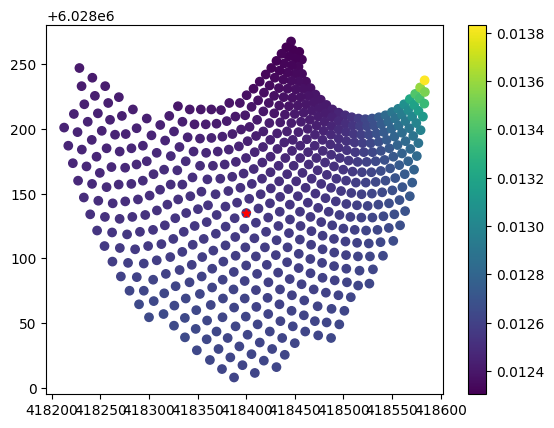

In [ ]:
plt.scatter(nx[sg[1]], ny[sg[1]], c=bias_av.values)
plt.colorbar()

plt.scatter(nx[sg[0]], ny[sg[0]], marker="*", color="red")


In [ ]:
def hops_to_center(edge_index, n_nodes, center_local_idx):
    """Number of hops from every sub-graph node to the central node.

    Args:
        edge_index: ``(2, n_edges)`` tensor/array of *local* node indices, as
            returned in a partition by ``graph_utils`` (self-loops are ignored).
        n_nodes: Number of nodes in the sub-graph (``len(subgraph_nodes)``).
        center_local_idx: Local index of the center node within the sub-graph.

    Returns:
        ``(n_nodes,)`` int array of hop counts, aligned with ``subgraph_nodes``
        (local index order); the center is 0. Unreachable nodes stay -1.
    """
    from collections import deque

    ei = np.asarray(edge_index)
    adjacency = [[] for _ in range(n_nodes)]
    for src, dst in zip(ei[0], ei[1]):
        if src != dst:  # skip self-loops
            adjacency[int(src)].append(int(dst))
            adjacency[int(dst)].append(int(src))  # add the reverse direction too

    hops = np.full(n_nodes, -1, dtype=int)
    hops[center_local_idx] = 0
    queue = deque([center_local_idx])
    while queue:
        current = queue.popleft()
        for neighbour in adjacency[current]:
            if hops[neighbour] == -1:
                hops[neighbour] = hops[current] + 1
                queue.append(neighbour)
    return hops

In [ ]:
hops = hops_to_center(sg[2], len(sg[1]), np.where(sg[1] == sg[0])[0][0])

In [ ]:
check = np.where(hops == 25)[0][0]

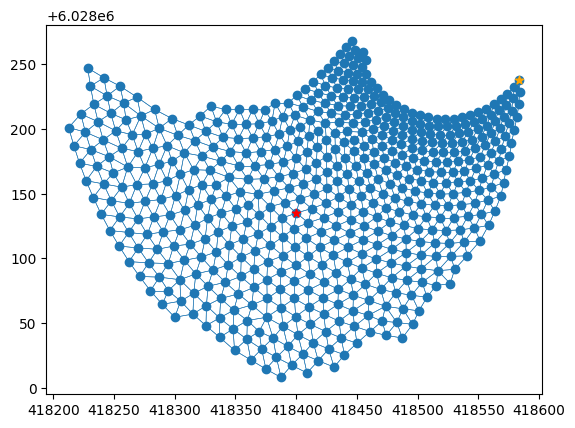

In [ ]:
fig, ax = plt.subplots(1, 1)

ax.scatter(nx[sg[1]], ny[sg[1]])

ax.scatter(nx[sg[0]], ny[sg[0]], marker="*", color="red")
ax.scatter(nx[sg[1][check]], ny[sg[1][check]], marker="*", color="orange")


# edges
edge_index = sg[2]

edge_src = edge_index[0].numpy()
edge_dst = edge_index[1].numpy()
mask = edge_src != edge_dst
global_src = sg[1][edge_src[mask]]  # local -> global node id
global_dst = sg[1][edge_dst[mask]]

segments = np.stack(
    [np.column_stack([nx[global_src], ny[global_src]]),
     np.column_stack([nx[global_dst], ny[global_dst]])],
    axis=1,
)
ax.add_collection(
    LineCollection(segments, colors=["C0"], linewidths=0.4, alpha=1.0, zorder=0)
)

In [ ]:
import numpy as np
import pandas as pd

predicted = ds_merged.isel(experiment=0)["sigWaveHeight"]
true = ds_merged.isel(experiment=1)["sigWaveHeight"]

# 1) Expensive time-reduction done ONCE for the whole domain (not per partition)
error = predicted - true  # (time, node), lazy if dask-backed
node_rmse = np.sqrt((error ** 2).mean(dim="time")).compute()  # (node,)
node_bias = error.mean(dim="time").compute()                   # (node,)

# 2) Fast node_id -> array-position lookup, built once
node_ids_full = node_rmse["nSCHISM_hgrid_node"].values
node_pos = pd.Series(np.arange(len(node_ids_full)), index=node_ids_full)

node_rmse_vals = node_rmse.values
node_bias_vals = node_bias.values

# 3) Loop partitions only for the cheap part: BFS hops per subgraph
records = []
for pid, sg in enumerate(partitions):
    node_ids, edge_index, center_id = sg[1], sg[2], sg[0]
    center_local_idx = np.where(node_ids == center_id)[0][0]
    hops = hops_to_center(edge_index, len(node_ids), center_local_idx)

    pos = node_pos.loc[node_ids].values
    records.append(pd.DataFrame({
        "partition": pid,
        "node_id": node_ids,
        "hops": hops,
        "rmse": node_rmse_vals[pos],
        "bias": node_bias_vals[pos],
    }))

df = pd.concat(records, ignore_index=True)

# since there's no node overlap, each node appears exactly once total --
# this df has exactly n_partitions * 500 rows, one hop/rmse/bias triple per node

In [ ]:
import numpy as np
import pandas as pd

# --- 1) build a per-node hops lookup for the WHOLE domain, once ---
all_node_ids, all_hops = [], []
for sg in partitions:
    node_ids, edge_index, center_id = sg[1], sg[2], sg[0]
    center_local_idx = np.where(node_ids == center_id)[0][0]
    hops = hops_to_center(edge_index, len(node_ids), center_local_idx)
    all_node_ids.append(node_ids)
    all_hops.append(hops)

all_node_ids = np.concatenate(all_node_ids)
all_hops = np.concatenate(all_hops)

# global lookup: domain node_id -> hops (NaN/-1 for nodes not covered by any partition)
node_ids_full = predicted["nSCHISM_hgrid_node"].values
hops_lookup = pd.Series(-1, index=node_ids_full)
hops_lookup.loc[all_node_ids] = all_hops
hops_full = hops_lookup.values  # (n_domain_nodes,), aligned with predicted/true node order

covered_mask = hops_full >= 0  # only nodes actually in a partition

# --- 2) bin definitions ---
HOPS_MAX = 25  # cap, given estuary-tail concerns discussed earlier
hops_bins = np.clip(hops_full[covered_mask], 0, HOPS_MAX)

change_bin_edges = np.array([-np.inf, -1.0, -0.5, 0.5, 1.0, np.inf])  # |ΔSWH| bins, tune to your data
n_change_bins = len(change_bin_edges) - 1

sq_err_sum = np.zeros((HOPS_MAX + 1, n_change_bins))
count = np.zeros((HOPS_MAX + 1, n_change_bins))

# --- 3) stream over time: cheap per-step, no giant array materialized ---
true_vals = true.values      # if this itself is too big to hold, chunk via dask/.isel loop instead
pred_vals = predicted.values

n_time = true_vals.shape[0]
for t in range(1, n_time):  # start at 1 since we need a diff
    change_t = true_vals[t, covered_mask] - true_vals[t - 1, covered_mask]  # signed, no abs    
    err_t = pred_vals[t, covered_mask] - true_vals[t, covered_mask]
    sq_err_t = err_t ** 2

    change_bin_idx = np.digitize(change_t, change_bin_edges) - 1
    change_bin_idx = np.clip(change_bin_idx, 0, n_change_bins - 1)

    np.add.at(sq_err_sum, (hops_bins.astype(int), change_bin_idx), sq_err_t)
    np.add.at(count, (hops_bins.astype(int), change_bin_idx), 1)

    if t % 100 == 0:
        print(t)

rmse_grid = np.sqrt(sq_err_sum / np.maximum(count, 1))  # (hops, change_bin)

100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400


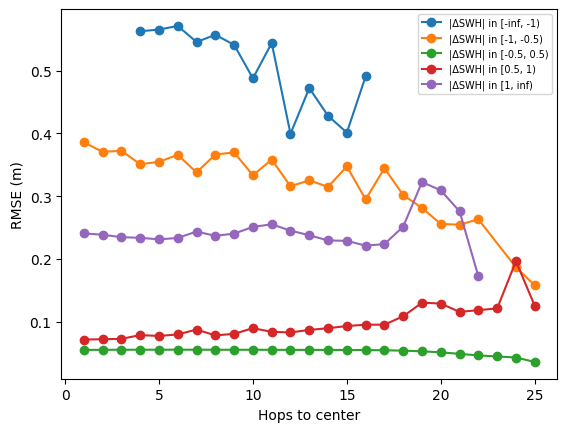

In [ ]:
fig, ax = plt.subplots()
for cb in range(n_change_bins):
    valid = count[:, cb] > 100  # drop bins with too few samples to trust
    label = f"|ΔSWH| in [{change_bin_edges[cb]:.2g}, {change_bin_edges[cb+1]:.2g})"
    ax.plot(np.arange(HOPS_MAX + 1)[valid], rmse_grid[valid, cb], "o-", label=label)

ax.set_xlabel("Hops to center")
ax.set_ylabel("RMSE (m)")
ax.legend(fontsize=7)
plt.show()

In [ ]:
(ds_true["sigWaveHeight"].diff(dim="time")> 1.0).sum().compute()

<xarray.DataArray 'sigWaveHeight' ()> Size: 8B
array(19519)
Attributes:
    i23d:          1
    location:      node
    grid_mapping:  crs
    mesh:          SCHISM_hgrid

In [ ]:
import numpy as np
import pandas as pd

experiments = ["swh-gat-500", "swh-gat-vn-500", "swh-gat-lstm-vn-6-500", "swh-gat-lstm-vn-48-500"]

all_count = {}
all_rmse_grid = {}

for experiment in experiments:

    ds_pred = xr.concat([xr.open_dataset(f"/work/ka1176/caroline/gitlab/wind-wave-model-emulator/logs/predict_2020/{experiment}/predictions_183-213.nc"),
                     xr.open_dataset(f"/work/ka1176/caroline/gitlab/wind-wave-model-emulator/logs/predict_2020/{experiment}/predictions_336-366.nc")],
                     dim="time")
    ds_merged = xr.concat([ds_pred, ds_true], dim="experiment", join="inner")
    true = ds_merged.isel(experiment=1)["sigWaveHeight"]
    pred = ds_merged.isel(experiment=0)["sigWaveHeight"]



    # --- 1) build a per-node hops lookup for the WHOLE domain, once ---
    all_node_ids, all_hops = [], []
    for sg in partitions:
        node_ids, edge_index, center_id = sg[1], sg[2], sg[0]
        center_local_idx = np.where(node_ids == center_id)[0][0]
        hops = hops_to_center(edge_index, len(node_ids), center_local_idx)
        all_node_ids.append(node_ids)
        all_hops.append(hops)

    all_node_ids = np.concatenate(all_node_ids)
    all_hops = np.concatenate(all_hops)

    # global lookup: domain node_id -> hops (NaN/-1 for nodes not covered by any partition)
    node_ids_full = predicted["nSCHISM_hgrid_node"].values
    hops_lookup = pd.Series(-1, index=node_ids_full)
    hops_lookup.loc[all_node_ids] = all_hops
    hops_full = hops_lookup.values  # (n_domain_nodes,), aligned with predicted/true node order

    covered_mask = hops_full >= 0  # only nodes actually in a partition

    # --- 2) bin definitions ---
    HOPS_MAX = 25  # cap, given estuary-tail concerns discussed earlier
    hops_bins = np.clip(hops_full[covered_mask], 0, HOPS_MAX)

    change_bin_edges = np.array([-np.inf, -1.0, 0, 1.0, np.inf])  # |ΔSWH| bins, tune to your data
    #change_bin_edges = np.array([-np.inf, -1.0, -0.5, 0.5, 1.0, np.inf])  # |ΔSWH| bins, tune to your data
    n_change_bins = len(change_bin_edges) - 1

    sq_err_sum = np.zeros((HOPS_MAX + 1, n_change_bins))
    count = np.zeros((HOPS_MAX + 1, n_change_bins))

    # --- 3) stream over time: cheap per-step, no giant array materialized ---
    true_vals = true.values      # if this itself is too big to hold, chunk via dask/.isel loop instead
    pred_vals = predicted.values

    n_time = true_vals.shape[0]
    for t in range(1, n_time):  # start at 1 since we need a diff
        change_t = true_vals[t, covered_mask] - true_vals[t - 1, covered_mask]  # signed, no abs    
        err_t = pred_vals[t, covered_mask] - true_vals[t, covered_mask]
        sq_err_t = err_t ** 2

        change_bin_idx = np.digitize(change_t, change_bin_edges) - 1
        change_bin_idx = np.clip(change_bin_idx, 0, n_change_bins - 1)

        np.add.at(sq_err_sum, (hops_bins.astype(int), change_bin_idx), sq_err_t)
        np.add.at(count, (hops_bins.astype(int), change_bin_idx), 1)

        if t % 100 == 0:
            print(t)

    rmse_grid = np.sqrt(sq_err_sum / np.maximum(count, 1))  # (hops, change_bin)

    all_count[experiment] = count
    all_rmse_grid[experiment] = rmse_grid

FileNotFoundError: [Errno 2] No such file or directory: '/work/ka1176/caroline/gitlab/wind-wave-model-emulator/logs/predict_2020/swh-gat-500/predictions_183-213.nc'

In [ ]:
fig, ax = plt.subplots()

for experiment in experiments:
    count = all_count[experiment]
    rmse_grid = all_rmse_grid[experiment]
    for i, cb in enumerate(range(n_change_bins)):
        valid = count[:, cb] > 100  # drop bins with too few samples to trust
        label = f"|ΔSWH| in [{change_bin_edges[cb]:.2g}, {change_bin_edges[cb+1]:.2g})"
        ax.plot(np.arange(HOPS_MAX + 1)[valid], rmse_grid[valid, cb], "o-", label=label, color=f"C{i}")

ax.set_xlabel("Hops to center")
ax.set_ylabel("RMSE (m)")
ax.legend(fontsize=7)
plt.show()

In [ ]:
cb

In [ ]:
fig, ax = plt.subplots()

for j, experiment in enumerate(experiments):
    count = all_count[experiment]
    rmse_grid = all_rmse_grid[experiment]
    for i, cb in enumerate(range(n_change_bins)):
        if cb != 3:
            continue
        valid = count[:, cb] > 100  # drop bins with too few samples to trust
        label = f"|ΔSWH| in [{change_bin_edges[cb]:.2g}, {change_bin_edges[cb+1]:.2g})"
        ax.plot(np.arange(HOPS_MAX + 1)[valid], rmse_grid[valid, cb], "o-", label=experiment, color=f"C{j}")

ax.set_xlabel("Hops to center")
ax.set_ylabel("RMSE (m)")
ax.legend(fontsize=7)
plt.show()

In [ ]:
all_count